# SOR experiments for Section 7 and Homework 3

- Start with Algorithm 7.3 and its textbook checks, then compare Jacobi, Gauss–Seidel, and SOR on Homework 3.
- The [Word report](SOR%20Findings%20Report.docx) summarizes the findings and explains how to read the counts.
- To reproduce the results, open this notebook from its folder, select a Python kernel with NumPy and Matplotlib, and choose **Run All**.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from IPython.display import Markdown, display
from sor_tools.experiments import (
    run_implementation_1,
    run_implementation_2,
)

## 1. Implement and verify the method

- Gauss–Seidel uses each newly updated value immediately. SOR multiplies each proposed correction by $\omega$.
- The test uses textbook Example 1, starting at $(1,1,1)$ with exact solution $(3,4,-5)$.
- The iterate table shows the starting guess (sweep 0) and the first seven sweeps. The count table separates accuracy against the exact solution from the algorithm's own stopping rule.

In [2]:
sweeps, counts = run_implementation_1()
display(Markdown("### Textbook Example 1 iterates\n\n" + sweeps))
display(Markdown("### Textbook Example 1 sweep counts\n\n" + counts))

### Textbook Example 1 iterates

| Sweep | Gauss–Seidel iterate | SOR iterate (ω = 1.25) |
| --- | --- | --- |
| 0 | (1.000000, 1.000000, 1.000000) | (1.000000, 1.000000, 1.000000) |
| 1 | (5.250000, 3.812500, -5.046875) | (6.312500, 3.519531, -6.650146) |
| 2 | (3.140625, 3.882812, -5.029297) | (2.622314, 3.958527, -4.600424) |
| 3 | (3.087891, 3.926758, -5.018311) | (3.133303, 4.010265, -5.096686) |
| 4 | (3.054932, 3.954224, -5.011444) | (2.957051, 4.007484, -4.973490) |
| 5 | (3.034332, 3.971390, -5.007153) | (3.003721, 4.002925, -5.005714) |
| 6 | (3.021458, 3.982119, -5.004470) | (2.996328, 4.000926, -4.998282) |
| 7 | (3.013411, 3.988824, -5.002794) | (3.000050, 4.000259, -5.000349) |

### Textbook Example 1 sweep counts

| Criterion | Gauss–Seidel sweeps | SOR sweeps (ω = 1.25) |
| --- | --- | --- |
| True error below 5 × 10⁻⁸ | 34 | 14 |
| Change between sweeps below 10⁻⁷ | 32 | 15 |

## 2. Compare choices of $\omega$

- Homework 3 Problem 12(b) starts from $(0,0,0)$ for all three methods. Problem 12(b) asks for the Jacobi sweeps, and Problem 13(b) repeats the same system with Gauss–Seidel.
- Each count measures sweeps until the largest component error falls below $5\times 10^{-8}$.
- The selected $\omega$ minimizes the spectral radius on the numerical grid. Example 1 reaches the error target in 14 sweeps at the nearby value $\omega=1.25$.
- Homework 3 Problem 14 benefits from under-relaxation. Jacobi reaches the target in just three sweeps on Problem 15.
- The error table shows the largest component error at each sweep. A dash marks sweeps after that method first reached the error target.
- The last table shows selected points from the Example 1 parameter sweep, including the observed sweep count and the spectral radius that predicts the long-run rate.

### Homework 3 Problem 12(b)

| Method | Sweep 1 | Sweep 2 | Sweeps to the error target |
| --- | --- | --- | --- |
| Jacobi | (0.900000, 0.700000, 0.600000) | (0.970000, 0.910000, 0.740000) | 12 |
| Gauss–Seidel | (0.900000, 0.790000, 0.758000) | (0.979000, 0.949500, 0.789900) | 7 |
| SOR (ω = 1.013) | (0.911700, 0.801455, 0.770175) | (0.981035, 0.954097, 0.791088) | 6 |

### Homework 3 Problem 12(b) error by sweep

| Sweep | Jacobi | Gauss–Seidel | SOR (ω = 1.013) |
| --- | --- | --- | --- |
| 0 | 9.958e-01 | 9.958e-01 | 9.958e-01 |
| 1 | 2.579e-01 | 1.679e-01 | 1.564e-01 |
| 2 | 5.158e-02 | 1.679e-02 | 1.475e-02 |
| 3 | 1.289e-02 | 8.395e-04 | 1.929e-04 |
| 4 | 2.579e-03 | 4.197e-05 | 4.550e-06 |
| 5 | 6.447e-04 | 2.099e-06 | 5.445e-08 |
| 6 | 1.289e-04 | 1.049e-07 | 9.745e-10 |
| 7 | 3.224e-05 | 5.247e-09 | — |
| 8 | 6.447e-06 | — | — |
| 9 | 1.612e-06 | — | — |
| 10 | 3.224e-07 | — | — |
| 11 | 8.059e-08 | — | — |
| 12 | 1.612e-08 | — | — |

### Results across the five systems

| System | Selected ω | Jacobi | Gauss–Seidel | Relaxed solver |
| --- | --- | --- | --- | --- |
| Example 1 | 1.241 | 78 | 34 | 15 |
| HW3 #12(a) | 1.016 | 20 | 13 | 12 |
| HW3 #12(b) | 1.013 | 12 | 7 | 6 |
| HW3 #14 | 0.835 | Diverges | 30 | 16 |
| HW3 #15 | 0.250 | 3 | Diverges | 212 |

### Section 7 Example 1 at selected ω values

| ω | Spectral radius | Sweeps to the error target |
| --- | --- | --- |
| 0.80 | 0.7464 | 51 |
| 1.00 | 0.6250 | 34 |
| 1.20 | 0.4000 | 18 |
| 1.22 | 0.3532 | 14 |
| 1.24 | 0.2560 | 15 |
| 1.25 | 0.2500 | 14 |
| 1.50 | 0.5000 | 28 |

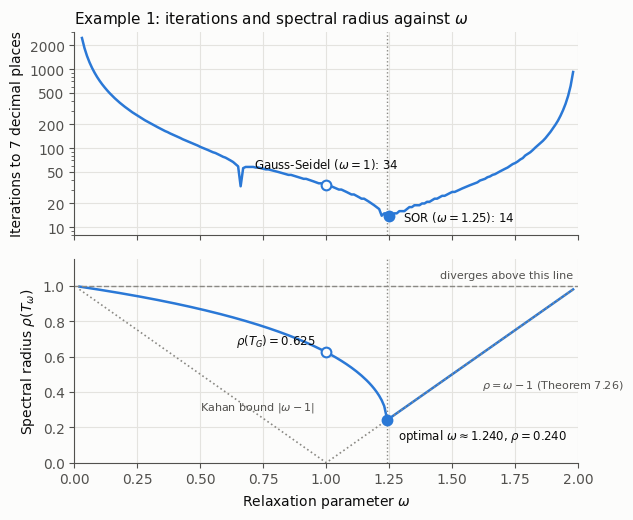

In [3]:
tables, parameter_plot = run_implementation_2()
for title, table in tables:
    display(Markdown(f"### {title}\n\n{table}"))
display(parameter_plot)
plt.close(parameter_plot)